# Name :- Anuj Thakre
# Class :- A_A2_20

In [1]:
import pandas as pd
df=pd.read_csv("winequality-red.csv")

In [2]:
df.head

<bound method NDFrame.head of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.067  

In [3]:
df.shape

(1599, 12)

In [4]:
df.describe

<bound method NDFrame.describe of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.0

## Uniavarient analysis

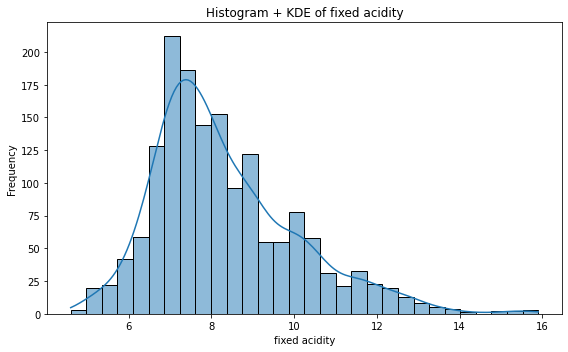

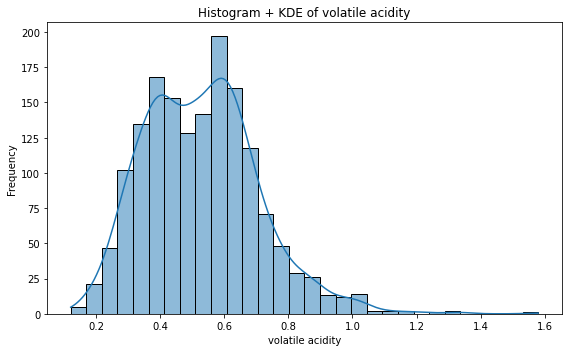

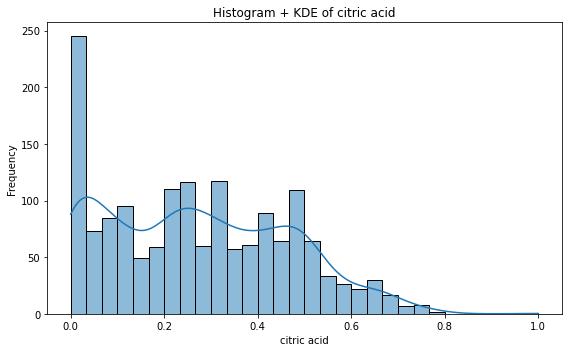

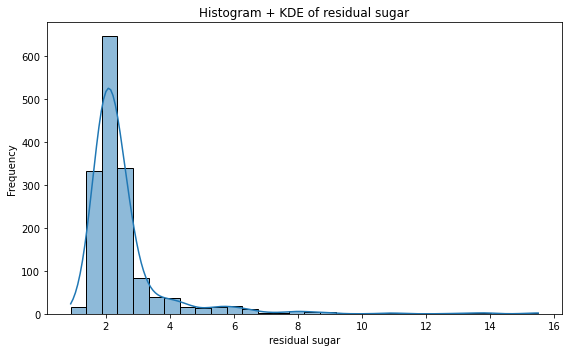

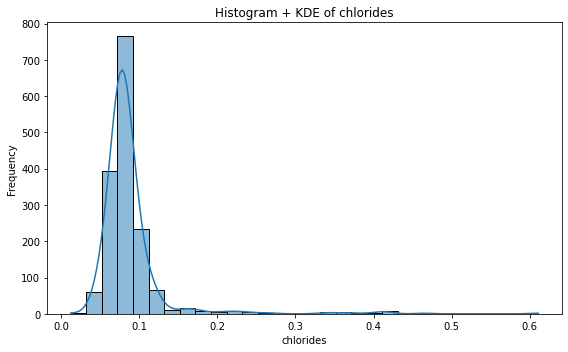

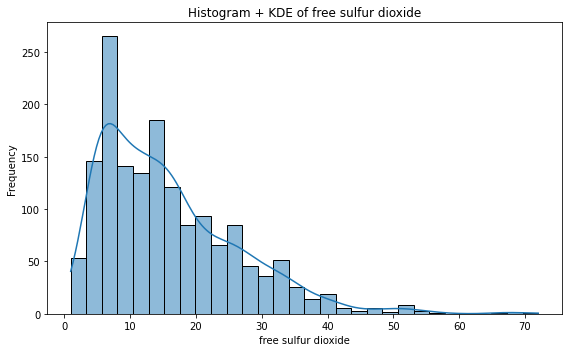

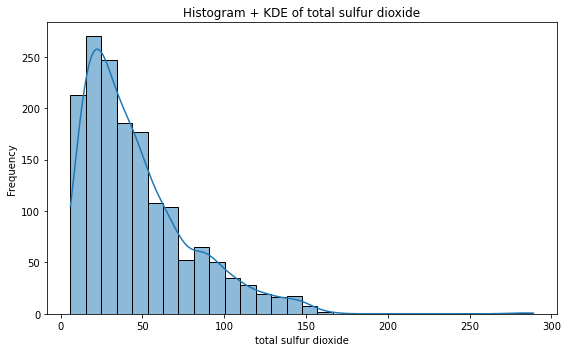

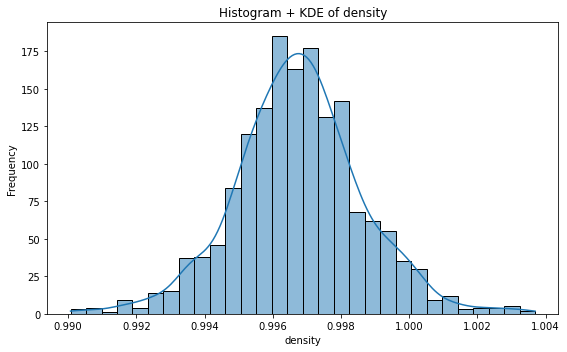

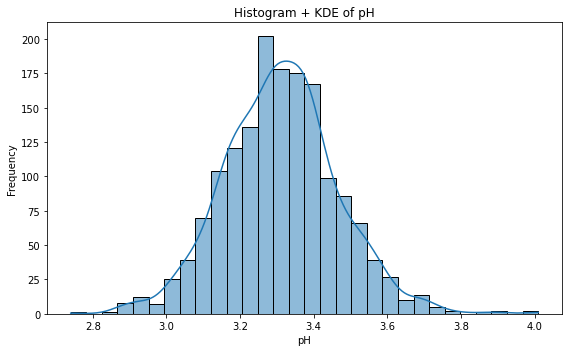

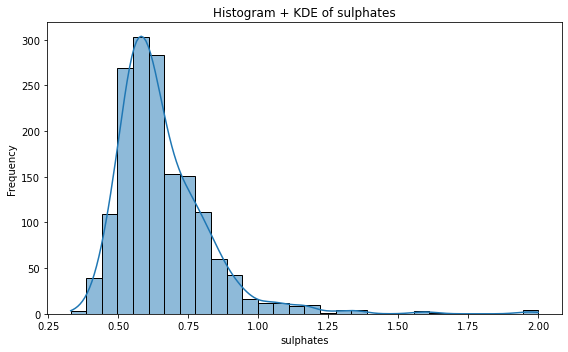

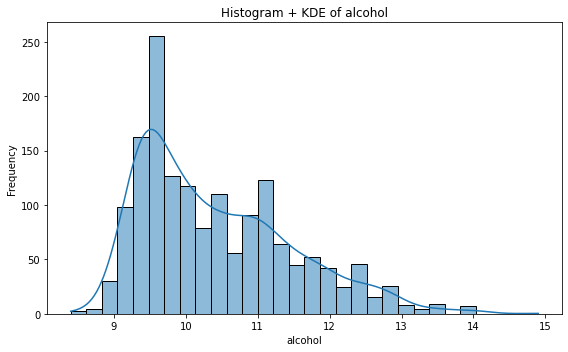

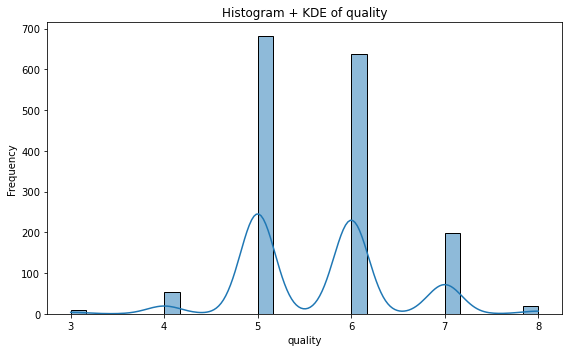

In [11]:
# Univariate Analysis
# Histogram + KDE

import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=col, kde=True, bins=30)
    plt.title(f'Histogram + KDE of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

## Boxplot - Outlier Analysis

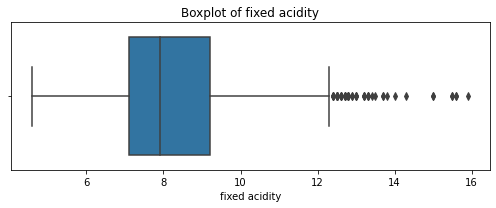

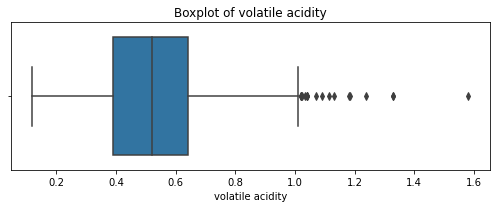

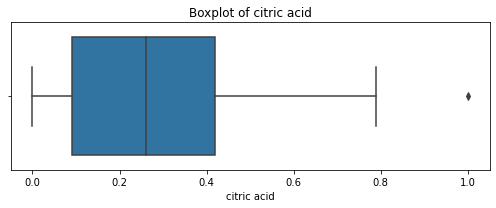

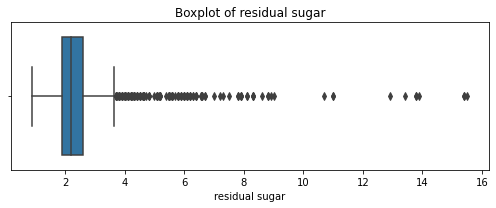

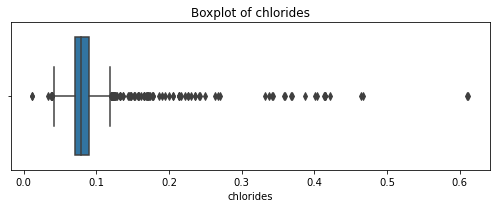

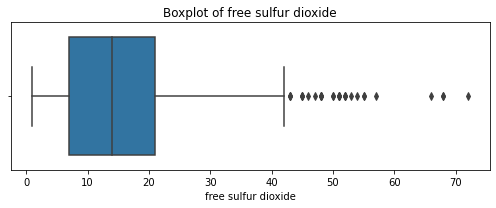

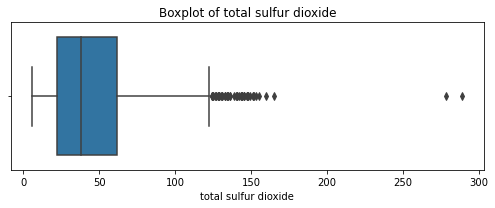

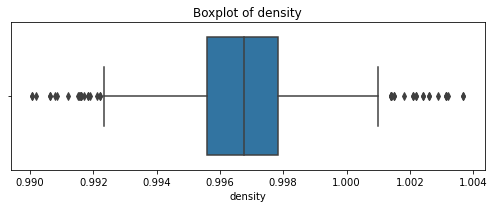

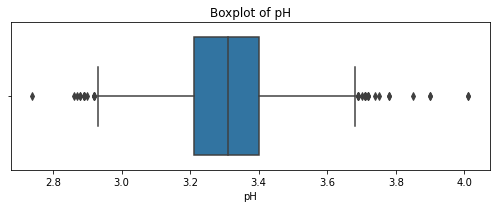

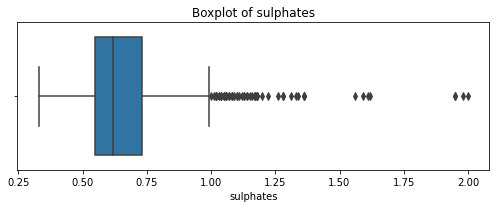

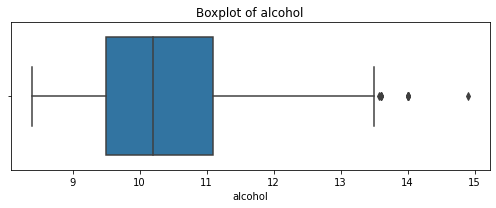

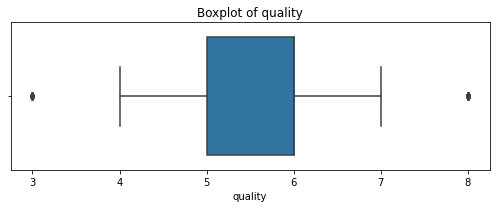

In [12]:
# Boxplot - Outlier Analysis

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(data=df, x=col)
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [8]:
# Detect outliers for every feature

features = df.drop(columns=['quality'])

# Calculate Q1 and Q3
Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Detect outliers
outlier_mask = (features < lower_bound) | (features > upper_bound)

# Count outliers for each feature
outlier_count = outlier_mask.sum()

# Percentage of outliers
outlier_percentage = (outlier_count / len(features)) * 100

# Create summary table
outlier_summary = pd.DataFrame({
    'Q1' : Q1,
    'Q3' : Q3,
    'IQR' : IQR, 
    'Lower bound' : lower_bound,
    'Upper bound' : upper_bound,
    'Outluer count' : outlier_count,
    'Qutlier % ' : outlier_percentage
})

# Display summary
# print(outlier_summary)
outlier_summary.round(3)

,Q1,Q3,IQR,Lower bound,Upper bound,Outluer count,Qutlier %
fixed acidity,7.100,9.200,2.100,3.950,12.350,49,3.064
volatile acidity,0.390,0.640,0.250,0.015,1.015,19,1.188
citric acid,0.090,0.420,0.330,-0.405,0.915,1,0.063
residual sugar,1.900,2.600,0.700,0.850,3.650,155,9.694
chlorides,0.070,0.090,0.020,0.040,0.120,112,7.004
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,30,1.876
total sulfur dioxide,22.000,62.000,40.000,-38.000,122.000,55,3.440
density,0.996,0.998,0.002,0.992,1.001,45,2.814
pH,3.210,3.400,0.190,2.925,3.685,35,2.189
sulphates,0.550,0.730,0.180,0.280,1.000,59,3.690


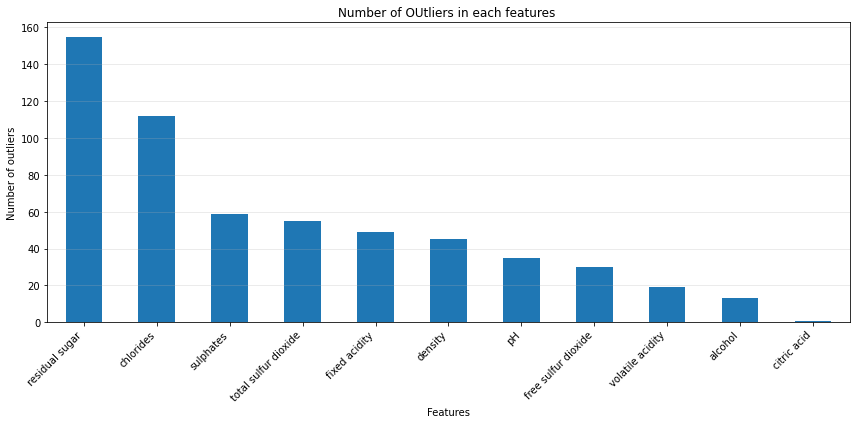

In [15]:
plt.figure(figsize=(12,6))

outlier_count.sort_values(ascending=False).plot(
  kind = 'bar'
)

plt.title("Number of OUtliers in each features ")
plt.xlabel("Features")
plt.ylabel("Number of outliers")
plt.xticks(rotation=45, ha = 'right')
plt.grid(axis= 'y', alpha=0.3)

plt.tight_layout()
plt.show()

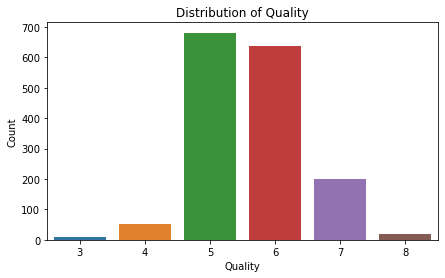

In [18]:
# Quality Distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.countplot(x='quality', data=df)
plt.title('Distribution of Quality')
plt.xlabel('Quality')
plt.ylabel('Count')
plt.show()

In [19]:
df['quality'].value_counts().sort_index()

3     10
4     53
5    681
6    638
7    199
8     18
Name: quality, dtype: int64

## Bivariate Analysis

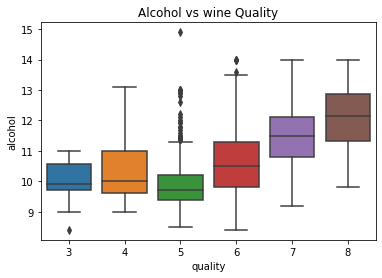

In [20]:
#Alchol vs Quality
sns.boxplot(x='quality',y='alcohol',data=df)
plt.title('Alcohol vs wine Quality')
plt.show()

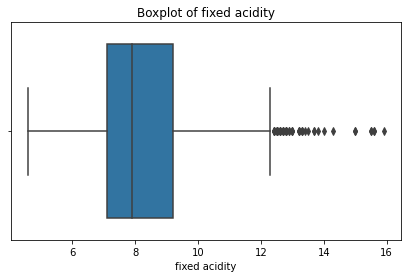

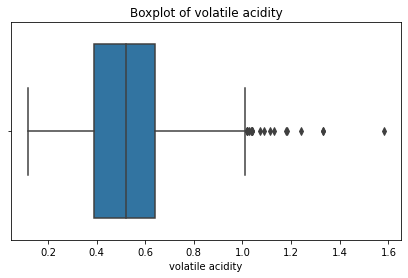

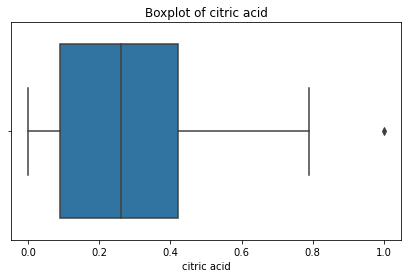

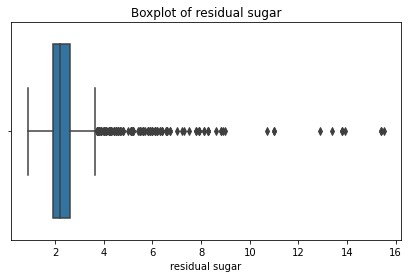

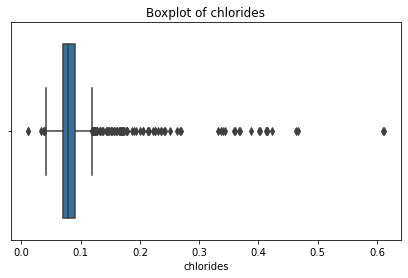

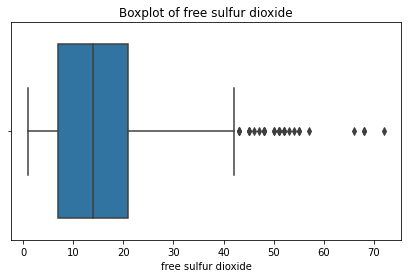

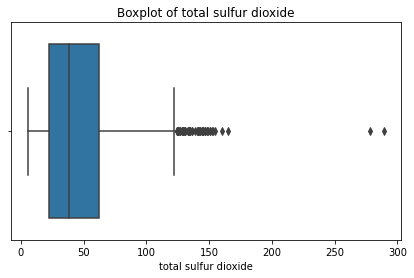

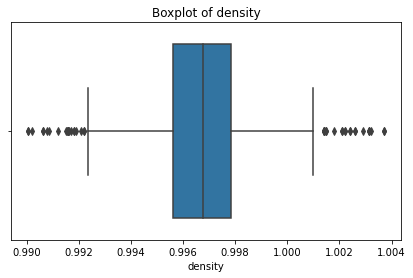

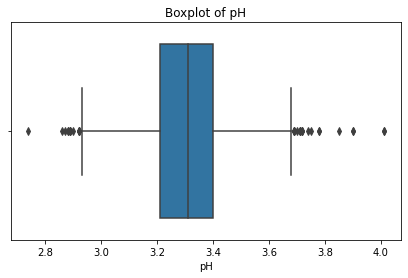

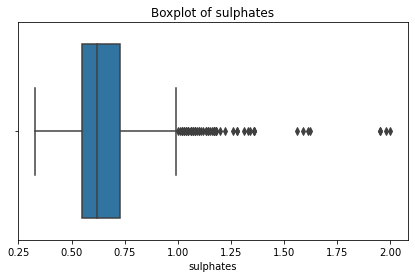

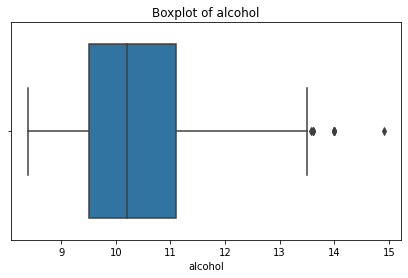

In [21]:
features = [
    'fixed acidity', 'volatile acidity', 'citric acid',
    'residual sugar', 'chlorides', 'free sulfur dioxide',
    'total sulfur dioxide', 'density', 'pH',
    'sulphates', 'alcohol'
]

for col in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

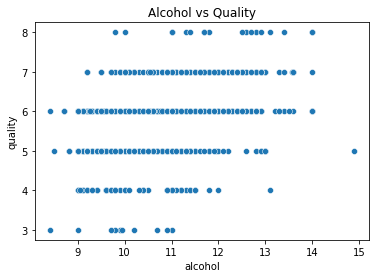

In [22]:
#Scatter Plot
sns.scatterplot(x='alcohol',y='quality',data=df)
plt.title('Alcohol vs Quality')
plt.show()

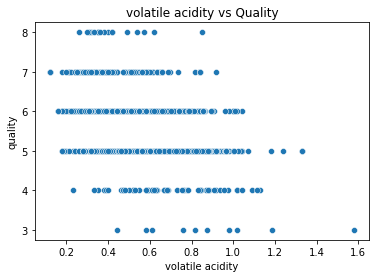

In [24]:
sns.scatterplot(x='volatile acidity', y = 'quality', data=df)
plt.title('volatile acidity vs Quality')
plt.show()

## Multivariate Analysis

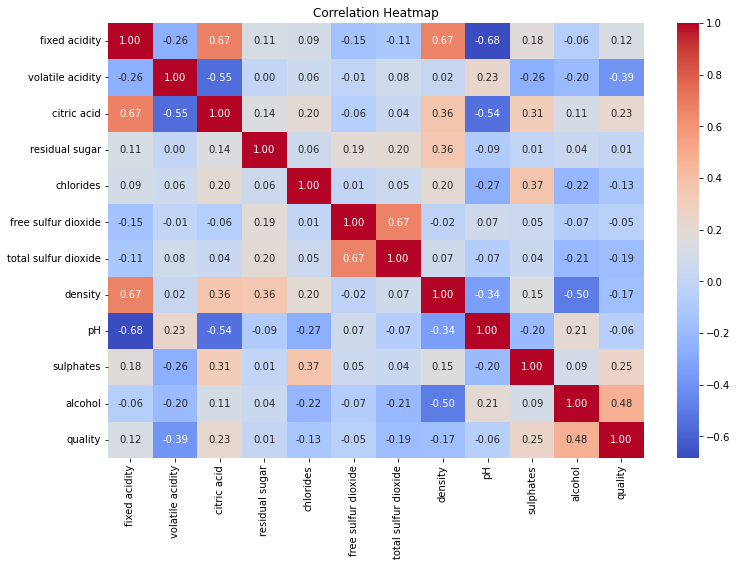

In [25]:
plt.figure(figsize=(12,8))

corr=df.corr()

sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

## Pair plot

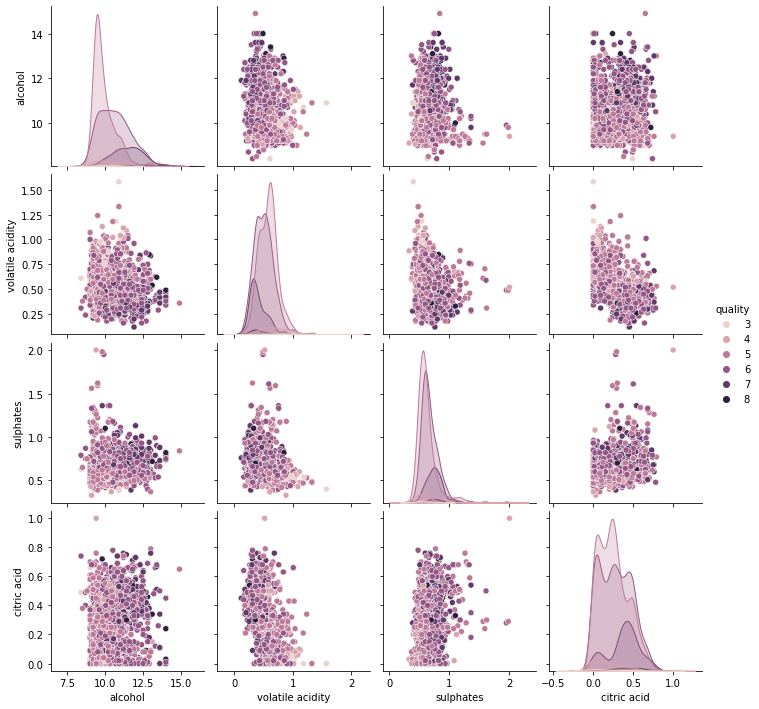

In [26]:
#Pair plot
selected =['alcohol','volatile acidity','sulphates','citric acid','quality']

sns.pairplot(df[selected],hue='quality')
plt.show()

In [27]:
# Multivariate Analysis Using Quality Groups

df['quality_group'] = pd.cut(
    df['quality'],
    bins=[0, 5, 7, 10],
    labels=['Low', 'Medium', 'High']
)

print(df[['quality', 'quality_group']].head())

   quality quality_group
0        5           Low
1        5           Low
2        5           Low
3        6        Medium
4        5           Low


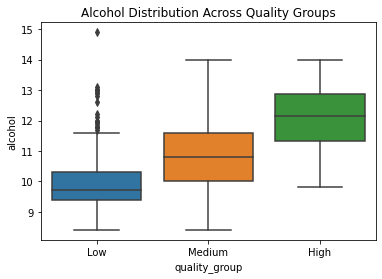

In [28]:
sns.boxplot(
    x='quality_group',
    y='alcohol',
    data=df

)
plt.title('Alcohol Distribution Across Quality Groups')
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import (accuracy_score,precision_score,recall_score,
                            f1_score,classification_report,
                            confusion_matrix,ConfusionMatrixDisplay)

In [26]:
X=df.drop('quality',axis=1)
y=df['quality']


In [27]:
print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (1599, 11)
y shape: (1599,)


In [28]:
print(y.value_counts().sort_index())

3     10
4     53
5    681
6    638
7    199
8     18
Name: quality, dtype: int64


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [30]:
criterion='entropy'

In [31]:
dt_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

In [45]:
df['quality_group'] = pd.cut(
  df['quality'],
  bins = [0,5,6,10],
  labels = ['low', 'medium', 'high']
)

In [32]:
print(X.columns)


Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='object')


In [33]:
print(X.select_dtypes(exclude='number').columns)

Index([], dtype='object')


In [34]:
y=df['quality']

In [35]:
# Features: remove target and quality group
X = df.drop(columns=['quality', 'quality_group'], errors='ignore')

# Target
y = df['quality']

In [36]:
print(X.select_dtypes(exclude='number').columns)

Index([], dtype='object')


In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [46]:
X = df.drop(columns=['quality', 'quality_group'], errors='ignore')
y = df['quality_group']

In [47]:
X = df.drop(columns=['quality', 'quality_group'], errors='ignore')
y = df['quality']

In [48]:
print(X.select_dtypes(exclude='number').columns)


Index([], dtype='object')


In [53]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (1279, 11)
X_test: (320, 11)
y_train: (1279,)
y_test: (320,)


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [50]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

dt_model.fit(X_train, y_train)


DecisionTreeClassifier(criterion='entropy', random_state=42)

In [55]:
y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

In [56]:
training_accuracy = accuracy_score(y_train, y_train_pred)
print("training accuracy :- ", training_accuracy)

training accuracy :-  1.0


In [57]:
test_accuracy = accuracy_score(y_test, y_test_pred)
print("test accuracy :- ", test_accuracy)

test accuracy :-  0.59375


In [58]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.11      0.09      0.10        11
           5       0.66      0.64      0.65       136
           6       0.58      0.62      0.60       128
           7       0.53      0.53      0.53        40
           8       0.50      0.33      0.40         3

    accuracy                           0.59       320
   macro avg       0.40      0.37      0.38       320
weighted avg       0.59      0.59      0.59       320



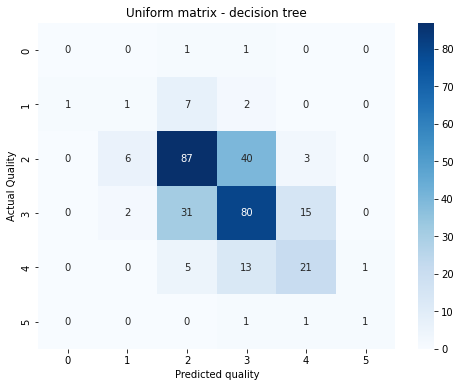

In [64]:
# confusion matrix :- 
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize= (8,6))

sns.heatmap(cm, annot= True, fmt='d', cmap='Blues')

plt.xlabel('Predicted quality')
plt.ylabel('Actual Quality')
plt.title('Uniform matrix - decision tree')

plt.show()

In [65]:
print("Tree depth :", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())

Tree depth : 19
Number of leaves: 297


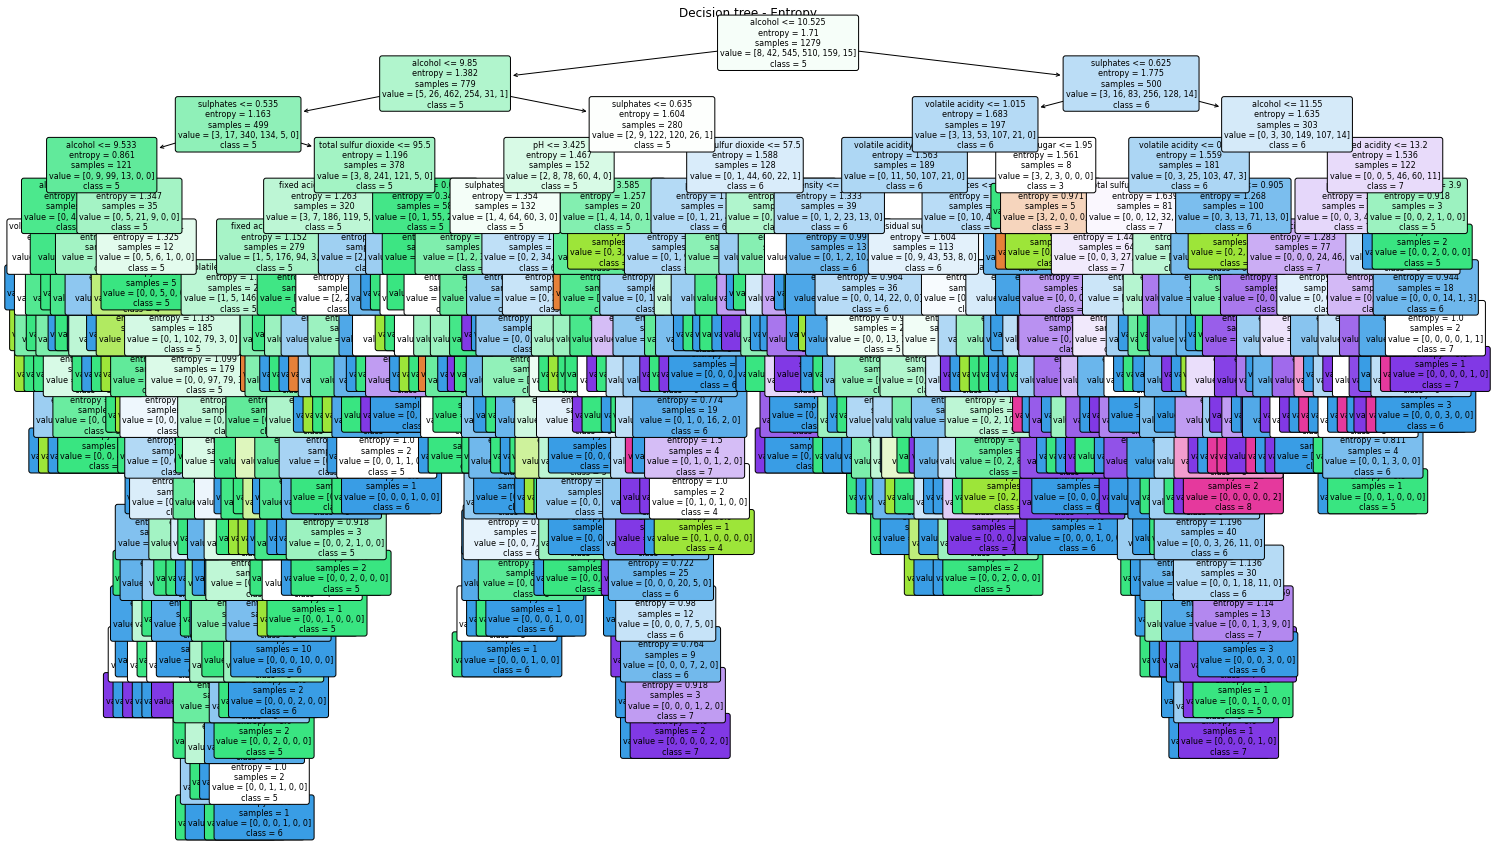

In [68]:
plt.figure(figsize=(25,15))

plot_tree(
    dt_model,
    feature_names= X.columns,
    class_names = [str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize = 8
)

plt.title("Decision tree - Entropy")
plt.show()

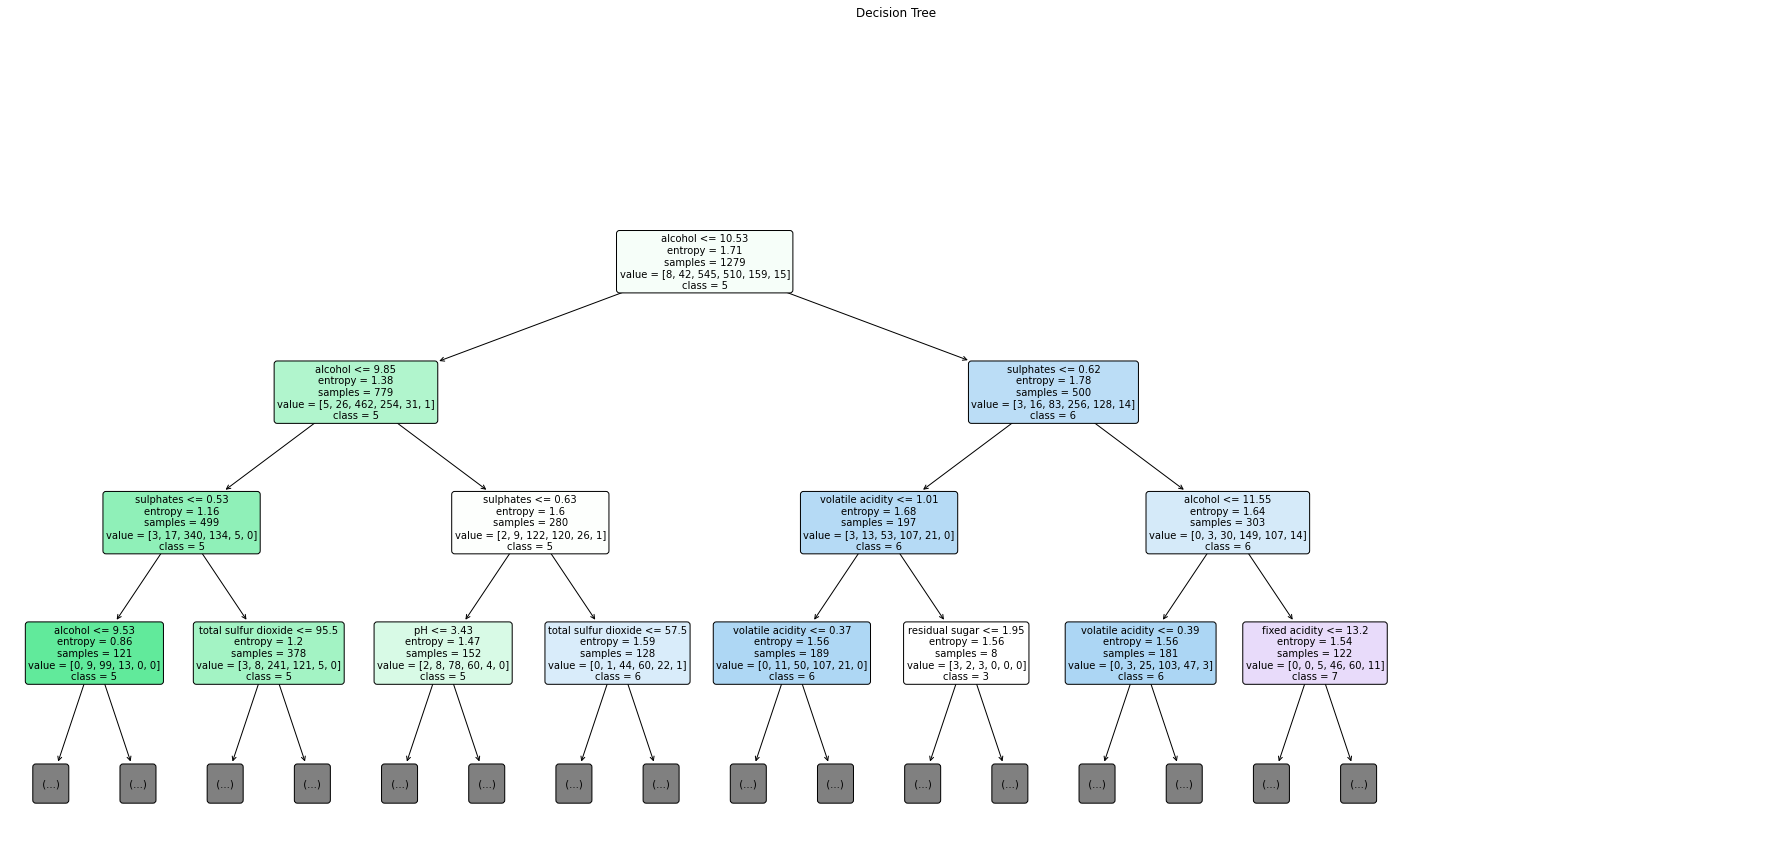

In [69]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(25,12))
plot_tree(dt_model,feature_names=X.columns,class_names=[str(c) for c in sorted(y.unique())],
          fontsize=10,
          filled=True,
          rounded=True,
          impurity= True,
          precision=2,
          max_depth=3
          )

plt.title("Decision Tree")
plt.tight_layout()
plt.show()